In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp



beta_A = 0.3  # Guessed daily algae growth
C_A = 0.02  # More educated guess of how much algae the shrimp eat L/(shrimp day)
C_S = 0.4 # Guess of how much shrimp the birds eat
gamma_S = 0.2  # algae-to-shrimp conversion
gamma_B = 0.3 # shrimp-to-bird conversion
delta_B = 0.12 # bird death rate
K = 50.0       # algae carrying capacity
delta_S = 0.03  # shrimp mortality


y0 = np.array([1.0, 10.0, 1.0])  # Initial conditions: shrimp, algae, birds
T = 400.0

## Lake Volume and Salinity

To model the change in lake volume and salinity we take inspiration from Mohammed & Tarboton's physical model. They model the lake with mulitple basins and tributaries; we start by simplifying to a single lake basin with two quantities: Water Volume ($V$) and Salt Mass ($M$). Salt mass varies only slighlty with inflow from rivers and outflow from mining, but we keep it constant for now.  Water volume increases based on river inflow $R$ and precipitation $P$, and decreases from evaporation. To start simple, we assume inflow from rives and precipitation to be linear. Evaporation is slightly more complicated and depends on both lake surface area and salinity ($N = M/V$). As additional simplifying assumptions, we model surface area and volume as a linear relationship ($A_{w}V$) and evaporation in a similar manner as a carrying capacity ($1 - nN$), since water evaporates slower with a higher concentration of dissolved salt ions. 

$$
\frac{dV}{dt} = R + P - A_{w}V(1 - nN)
$$

$$
\frac{dM}{dt} = 0
$$

Further iterations can incorporate nonlinear water inflow functions (seasonal, varying precipitation), more complicated surface area functions, and a non-constant salt mass function.

| Parameter | Meaning | Value | Units | Brief justification |
|---|---|---|---|---|
| $V$ | Water Volume
| $M$ | Total Salt Mass
| $N$ | Water Salinity ($M/V$)
| $R$ | Water Inflow from Rivers 
| $P$ | Water Inflow from Precipitation 
| $A_{w}$ | Constant expressing the relationship between Volume and Surface Area |
| $n$ | Salinity Suppression Coefficient |



In [4]:
def gsl_water_model(t, y, R, P, A_w, n, M_fixed):
    V = y[0]
    
    if V <= 0:
        return [0.0]
    
    N = M_fixed / V
    
    evap_factor = max(0.0, 1.0 - n * N)
    E = A_w * V * evap_factor
    dVdt = R + P - E
    
    return [dVdt]


# --- Parameters ---
R = 2.5       # River inflow (km^3/year)
P = 0.5       # Precipitation (km^3/year)
A_w = 0.15    # Surface-area-to-volume proportionality constant
n = 0.5       # Salinity suppression coefficient
M_fixed = 4.5 # Constant salt mass (billion metric tons)

# --- Initial Conditions & Time Span ---
V_initial = [20.0]        # Initial volume in km^3
t_span = (0.0, 50.0)      # Simulate over 50 years
t_eval = np.linspace(0, 50, 200)

# --- Solve ODE ---
sol = solve_ivp(
    fun=gsl_water_model, 
    t_span=t_span, 
    y0=V_initial, 
    args=(R, P, A_w, n, M_fixed), 
    t_eval=t_eval,
    method='RK45'
)

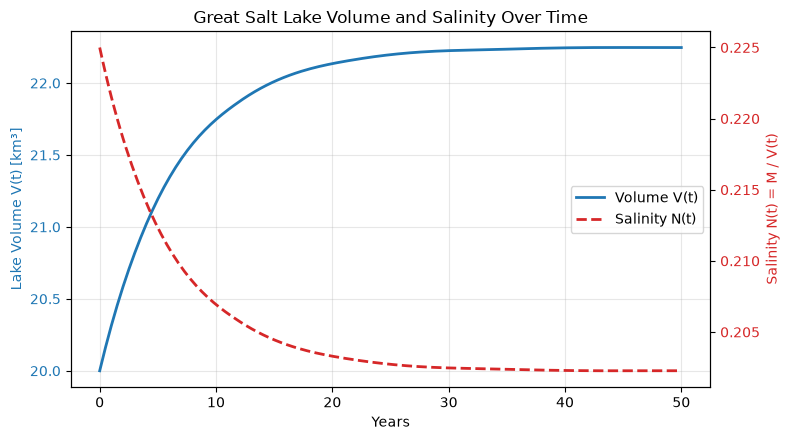

In [6]:
# --- Plot Both on the Same Graph (Dual Y-Axis) ---
fig, ax1 = plt.subplots(figsize=(8, 4.5))

# Left axis: Lake Volume V(t)
color1 = 'tab:blue'
ax1.set_xlabel('Years')
ax1.set_ylabel('Lake Volume V(t) [km³]', color=color1)
line1 = ax1.plot(sol.t, sol.y[0], color=color1, lw=2, label='Volume V(t)')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, alpha=0.3)

# Right axis: Salinity N(t)
ax2 = ax1.twinx()
color2 = 'tab:red'
ax2.set_ylabel('Salinity N(t) = M / V(t)', color=color2)
salinity = M_fixed / sol.y[0]
line2 = ax2.plot(sol.t, salinity, color=color2, lw=2, linestyle='--', label='Salinity N(t)')
ax2.tick_params(axis='y', labelcolor=color2)

# Combine legends from both axes
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right')

plt.title('Great Salt Lake Volume and Salinity Over Time')
fig.tight_layout()
plt.show()

Since the model is one dimensional, there is a single stable equilibrium regardless of the initial conditions. 

# TODO 
Change the phase 2 equations to depend on V with inspiration from the Belovsky Papers.
- Change algae carrying capacity to scale linearly with V (K turns into carrying capacity per volume)
- modify growth rates (beta_A) and shrimp conversion (gamma_S) with a bell-shaped salinity performance function
- Scale interaction rates C_A and C_S by volume


Looks something like:


**Algae Population ($A$):**
$$\frac{dA}{dt} = \beta_A f(N) A \left(1 - \frac{A}{k_0 V}\right) - C_A S A$$

**Brine Shrimp Population ($S$):**
$$\frac{dS}{dt} = \gamma_S f(N) C_A S A - C_S S B - \delta_S S$$

**Migratory Bird Population ($B$):**
$$\frac{dB}{dt} = -\delta_B B + \gamma_B C_S S B$$

Where the salinity tolerance function $f(N)$ is defined as:
$$f(N) = \exp\left( - \left(\frac{N - N_{\text{opt}}}{\sigma}\right)^2 \right)$$
